# EMIT collocation with CERES

In [1]:
import xarray as xr
import netCDF4,os,re,copy,glob
import numpy as np
import matplotlib.pyplot as plt
from EMIT_lib import *
from CERES_lib import *
import requests
import pickle
import cartopy
import sys,os,glob,datetime
import cartopy.crs as crs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from AWS_Utils import get_NASA_creds
import awscli, s3fs, boto3

## necessary libraries and modules

### import NASA AWS credentials

In [2]:
lpdaac_creds = get_NASA_creds('lpdaac')
fs_s3 = s3fs.S3FileSystem(anon=False, 
                          key=lpdaac_creds['accessKeyId'], 
                          secret=lpdaac_creds['secretAccessKey'], 
                          token=lpdaac_creds['sessionToken'])

In [3]:
# Define a S3 client
s3Client = boto3.client(
    's3',
    aws_access_key_id=lpdaac_creds['accessKeyId'],
    aws_secret_access_key=lpdaac_creds['secretAccessKey'],
    aws_session_token=lpdaac_creds['sessionToken'])

### a simple code to read in all the EMIT data product needed

In [4]:
def read_single_EMIT_granule_data(unique_time_stamp,products2read):
    '''
    Inputs: 
    unique_time_stamp" '20231227T091713' the unique time stamp to track EMIT data
    products2read: list of products to read e.g., ['RAD','RFL','MIN']
    Outputs:
    RAD: Radiance data
    RFL: Surface reflectance data
    
    '''
    response = requests.get('https://data.lpdaac.earthdatacloud.nasa.gov/s3credentials')
    temp_creds_req = response.json()
    fs_s3 = s3fs.S3FileSystem(anon=False, 
                          key=temp_creds_req['accessKeyId'], 
                          secret=temp_creds_req['secretAccessKey'], 
                          token=temp_creds_req['sessionToken'])
    RAD_bucket_prefix='s3://lp-prod-protected/EMITL1BRAD.001/'
    RAD_file_prefix='EMIT_L1B_RAD_001_'
    RFL_bucket_prefix='s3://lp-prod-protected/EMITL2ARFL.001/'
    RFL_file_prefix='EMIT_L2A_RFL_001_'
    MIN_bucket_prefix='s3://lp-prod-protected/EMITL2BMIN.001/'
    MIN_file_prefix='EMIT_L2B_MIN_001_'
    EMIT_granule_data={}
    for d in products2read:
        if d=='RAD' or d=='OBS':
            bucket = os.path.join(RAD_bucket_prefix, RAD_file_prefix+unique_time_stamp+'_*')
            #print(bucket)
            subdir = fs_s3.glob(bucket)
            product_files =  fs_s3.glob(os.path.join(subdir[0],'*'+d+'*.nc'))
            if len(product_files) ==1:
                s3_file_obj = fs_s3.open('s3://'+product_files[0], mode='rb')
                #print('reading...',product_files[0])
                #print(s3_file_obj.group())
                EMIT_granule_data[d]=xr.open_dataset(s3_file_obj, engine='h5netcdf')
               
                EMIT_granule_data[d+'_location']=xr.open_dataset(s3_file_obj,
                                                   group="/location",
                                                   engine='h5netcdf')

                EMIT_granule_data[d+'_sensor_band_parameters']=xr.open_dataset(s3_file_obj,
                                                                   group="/sensor_band_parameters",
                                                                   engine='h5netcdf')
        elif d =='RFL':
            bucket = os.path.join(RFL_bucket_prefix, RFL_file_prefix+unique_time_stamp+'_*')
            #print(bucket)
            subdir = fs_s3.glob(bucket)
            product_files =  fs_s3.glob(os.path.join(subdir[0],'*'+d+'*.nc'))
            for p in product_files:
                if 'RFLUNCERT' in p: continue
                s3_file_obj = fs_s3.open('s3://'+p, mode='rb')
                #print('reading...',p)
                EMIT_granule_data[d]=xr.open_dataset(s3_file_obj, engine='h5netcdf')
            #print(product_files)
            # s3_file_obj = fs_s3.open('s3://'+ssh_files[0], mode='rb')
            #
    return EMIT_granule_data
        

### Leob05 angular distribution model

In [5]:
import read_Loeb05_ADM 
import importlib
importlib.reload(read_Loeb05_ADM)
ADM=read_Loeb05_ADM.Loeb05_ADM()
ADM.interpolate_ADM([26.194853] ,[37.285618] ,[250.88895])

array([1.0036])

In [6]:
ADM.azi

array([ 10,  30,  50,  70,  90, 110, 130, 150, 170, 180])

### kurudz spectral solar irradiance model

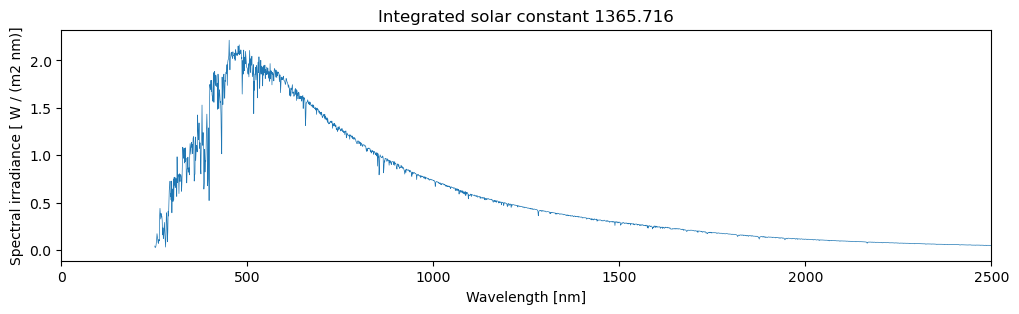

In [7]:
class kurudz_solar(object):
    def __init__(self):
        d=np.loadtxt('./data/solar_flux/kurudz_1.0nm.dat',skiprows=12)
        self.wavelength = d[:,0]
        self.spectral_irradiance=d[:,1]/1000.0 # convert mW / (m2 nm) to W/m2/nm
        self.solar_constant = np.trapz(self.spectral_irradiance,self.wavelength)
    def plot_spectral_irradiance(self):
        fig,ax=plt.subplots(figsize=(12,3))
        ax.plot(self.wavelength,self.spectral_irradiance,lw='0.5')
        ax.set_xlabel('Wavelength [nm]')
        ax.set_ylabel('Spectral irradiance [ W / (m2 nm)]')
        ax.set_title('Integrated solar constant {0:7.3f}'.format(self.solar_constant))
        ax.set_xlim([0,2500])
KS=kurudz_solar()
KS.plot_spectral_irradiance()


### great_circle_distance
simple routine to compute great circle distances between a bounch of points to an anchor point (lon0, lat0)

In [8]:
def great_circle(lon0, lat0, lon_array, lat_array):
    arc = np.arccos(np.sin(np.radians(lat0)) * np.sin(np.radians(lat_array))
                 + np.cos(np.radians(lat0)) * np.cos(np.radians(lat_array)) 
                 * np.cos(np.radians(lon0 - lon_array)))
    return 6371 * arc

## test the impacts of spectral resolution on broadband integration

In [9]:
case_stamp='20230429T095332'
EMIT_RAD = read_single_EMIT_granule_data(case_stamp,['RAD'])

0.033141289198756536


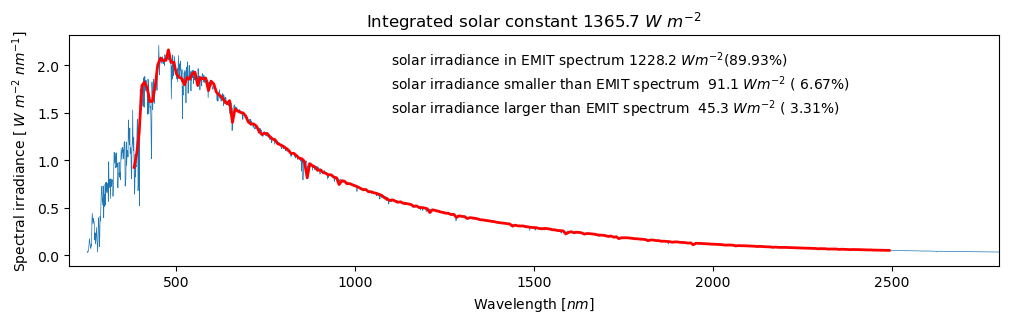

In [10]:
EMIT_wavelength = EMIT_RAD['RAD_sensor_band_parameters'].wavelengths.values
EMIT_wavelength_index = np.searchsorted(KS.wavelength,EMIT_wavelength)


fig,ax=plt.subplots(figsize=(12,3))
ax.plot(KS.wavelength,KS.spectral_irradiance,lw=0.5)
ax.plot(KS.wavelength[EMIT_wavelength_index],KS.spectral_irradiance[EMIT_wavelength_index],c='r',lw=2)
ax.set_xlabel(r'Wavelength [$nm$]')
ax.set_ylabel(r'Spectral irradiance [ $W \ m^{-2} \ nm^{-1}$]')
ax.set_title(r'Integrated solar constant'+ r'{0:7.1f}'.format(KS.solar_constant)+r' $W \ m^{-2}$')
ax.set_xlim([200,2800])

spectral_cover = (KS.wavelength>= EMIT_wavelength[0]) & (KS.wavelength<= EMIT_wavelength[-1])
larger_wavelength = KS.wavelength> EMIT_wavelength[-1]
smaller_wavelength = KS.wavelength<EMIT_wavelength[0]

S0_EMIT = np.trapz(KS.spectral_irradiance[spectral_cover],KS.wavelength[spectral_cover])
S0_EMIT_right = np.trapz(KS.spectral_irradiance[larger_wavelength],KS.wavelength[larger_wavelength])
S0_EMIT_left = np.trapz(KS.spectral_irradiance[smaller_wavelength],KS.wavelength[smaller_wavelength])

ax.text(1100,2.0,r'solar irradiance in EMIT spectrum ' +'{0:6.1f}'.format(S0_EMIT)+ ' $W m^{-2}$' +'({0:5.2f}%)'.format(S0_EMIT/KS.solar_constant*100))
ax.text(1100,1.75,r'solar irradiance smaller than EMIT spectrum'+ '{0:6.1f}'.format(S0_EMIT_left)+' $W m^{-2}$'+' ({0:5.2f}%)'.format(S0_EMIT_left/KS.solar_constant*100))
ax.text(1100,1.5,r'solar irradiance larger than EMIT spectrum'+ '{0:6.1f}'.format(S0_EMIT_right)+' $W m^{-2}$'+' ({0:5.2f}%)'.format(S0_EMIT_right/KS.solar_constant*100))

print(45.2615736058/KS.solar_constant)

## single case test

13.6464262008667
(1280, 1242, 3)
50 255


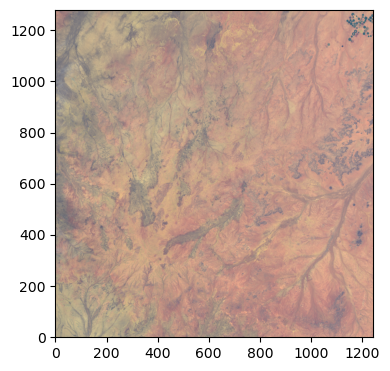

In [18]:
#print(RAD.data.shape)
R_idx,G_idx,B_idx=33,22,5
#R_idx,G_idx,B_idx=200,22,4
#pixel_yindex,pixel_xindex = [600,1200],[100,100] # ocean pixel and land pixel

#print(RAD.sensor_band_parameters['wavelengths'][[R_idx,G_idx,B_idx]])
#print(np.diff(RAD.sensor_band_parameters['wavelengths']))
case_stamp='20230406T071941'
EMIT_granule_data_dict = read_single_EMIT_granule_data(case_stamp,['RAD','OBS'])
scale_factor= np.max(np.array([EMIT_granule_data_dict['RAD'].radiance[:,:,R_idx].max(),
                               EMIT_granule_data_dict['RAD'].radiance[:,:,G_idx].max(),
                               EMIT_granule_data_dict['RAD'].radiance[:,:,B_idx].max()]))
print(scale_factor)
RGB=np.stack([EMIT_granule_data_dict['RAD'].radiance[:,:,R_idx]/scale_factor*255,
              EMIT_granule_data_dict['RAD'].radiance[:,:,G_idx]/scale_factor*255,
              EMIT_granule_data_dict['RAD'].radiance[:,:,B_idx]/scale_factor*255],axis=2)
RGB_image=np.array(RGB, dtype=np.uint8)
print(RGB.shape)
fig,ax=plt.subplots(figsize=[4,4],tight_layout=True)
ax.imshow(RGB_image,origin='lower')

print(RGB_image.min(),RGB_image.max())
# for px,py in zip(pixel_xindex,pixel_yindex):
#     ax.plot([px],[py],'o',c='r')
fig.savefig('EMIT_granlue'+case_stamp+'_RGB.png',dpi=300)

In [19]:
x= EMIT_granule_data_dict['RAD_sensor_band_parameters'].wavelengths
y= EMIT_granule_data_dict['RAD'].radiance.mean(axis=(0,1))
yvar = EMIT_granule_data_dict['RAD'].radiance.std(axis=(0,1))                                     

Text(0.5, 0.7, 'Mean Relative Azimuth  -27.32')

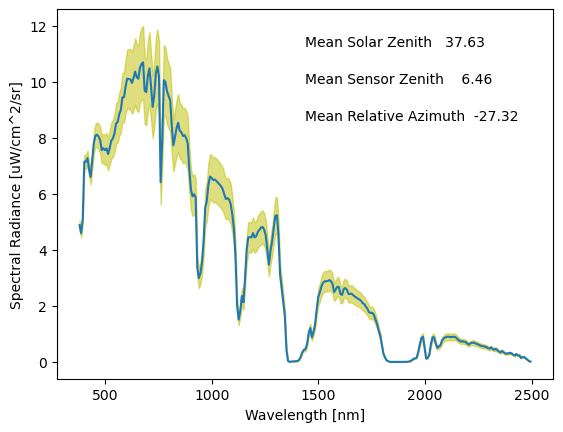

In [22]:
fig,ax=plt.subplots()
ax.plot(x,y)
ax.fill_between(x,y-yvar,y+yvar,alpha=0.5,color='y')
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Spectral Radiance [uW/cm^2/sr]')
ax.text(0.5,0.9,'Mean Solar Zenith {0:7.2f}'.format(EMIT_granule_data_dict['OBS'].obs[:,:,4].mean()),transform=ax.transAxes)
ax.text(0.5,0.8,'Mean Sensor Zenith {0:7.2f}'.format(EMIT_granule_data_dict['OBS'].obs[:,:,2].mean()),transform=ax.transAxes)
ax.text(0.5,0.7,'Mean Relative Azimuth {0:7.2f}'.format(EMIT_granule_data_dict['OBS'].obs[:,:,1].mean()-
                                                        EMIT_granule_data_dict['OBS'].obs[:,:,3].mean()),transform=ax.transAxes)
        

OCI wavelength starts at 314.5071105957031
EMIT wavelength starts at <xarray.DataArray 'wavelengths' ()> Size: 4B
array(381.00558, dtype=float32)
Attributes:
    long_name:  Wavelength Centers
    units:      nm


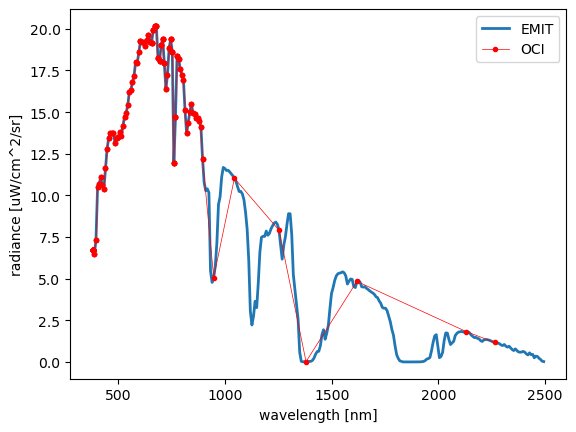

In [46]:
w=np.load('../PACE/OCI_wavelength.npz')
OCI_wavelength=w['arr_0']
EMIT_OCI_wl_index = np.searchsorted(x,OCI_wavelength)
EMIT_OCI_wl_samples = x[EMIT_OCI_wl_index]
EMIT_OCI_rad_samples = y[EMIT_OCI_wl_index]
fig,ax=plt.subplots()
ax.plot(EMIT_granule_data_dict['RAD_sensor_band_parameters'].wavelengths,
        EMIT_granule_data_dict['RAD'].radiance.mean(axis=(0,1)),lw=2.0,label='EMIT')
ax.plot(EMIT_OCI_wl_samples,EMIT_OCI_rad_samples,
        lw=0.5,marker='.',c='r',label='OCI')
ax.legend()
ax.set_xlabel('wavelength [nm]')
ax.set_ylabel('radiance [uW/cm^2/sr]')
print('OCI wavelength starts at',OCI_wavelength[0])
print('EMIT wavelength starts at',x[0])

In [49]:
print('spectral integration of EMIT',np.trapz(y,x)/100.0*np.pi)
print('spectral integration of OCI',np.trapz(EMIT_OCI_rad_samples,EMIT_OCI_wl_samples)/100.0*np.pi)


spectral integration of EMIT 426.09562286870846
spectral integration of OCI 446.7369297097292


In [23]:
importlib.reload(read_Loeb05_ADM)
EMIT_sza_mean = EMIT_granule_data_dict['OBS'].obs[:,:,4].mean()
EMIT_vza_mean = EMIT_granule_data_dict['OBS'].obs[:,:,2].mean()
EMIT_raa_mean = EMIT_granule_data_dict['OBS'].obs[:,:,1].mean()-\
                EMIT_granule_data_dict['OBS'].obs[:,:,3].mean()

ADM_value = ADM.interpolate_ADM([EMIT_sza_mean],[EMIT_vza_mean],[EMIT_raa_mean])
print(EMIT_sza_mean,EMIT_vza_mean,EMIT_raa_mean,ADM_value)

<xarray.DataArray 'obs' ()> Size: 4B
array(37.634266, dtype=float32) <xarray.DataArray 'obs' ()> Size: 4B
array(6.455782, dtype=float32) <xarray.DataArray 'obs' ()> Size: 4B
array(-27.324478, dtype=float32) [0.9599]


In [24]:
with open('EMIT_CERES_collocation/EMIT_TERRA_CERES_collocation/'+case_stamp+'.pkl', 'rb') as pkl_file:
    collocation_data=pickle.load(pkl_file)
print(collocation_data['CERES_file_name'][0])
CERES_data=xr.open_dataset(collocation_data['CERES_file_name'][0],engine='netcdf4')


/home/ubuntu/Research/EMIT_project/CERES_SSF/CER_SSF_Terra-FM2-MODIS_Edition4A_407405.2023040608.hdf


In [25]:
np.where(collocation_data['CERES_pixel_index'][0])

(array([42298, 42299, 42328, 42329, 42480, 42481, 42482]),)

In [26]:
EMIT_wavelength = EMIT_granule_data_dict['RAD_sensor_band_parameters'].wavelengths.values
EMIT_radiance   = EMIT_granule_data_dict['RAD'].radiance.values
nx,ny,ns = EMIT_radiance.shape
EMIT_BB_flux   = np.zeros([nx,ny])
for ix in range(nx):
    for iy in range(ny):
        EMIT_BB_flux[ix,iy]=np.pi/100.0*np.trapz(EMIT_radiance[ix,iy,:],EMIT_wavelength)/ADM_value

/tmp/ipykernel_999/2069672107.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  EMIT_BB_flux[ix,iy]=np.pi/100.0*np.trapz(EMIT_radiance[ix,iy,:],EMIT_wavelength)/ADM_value


In [18]:
EMIT_granule_data_dict.keys()

dict_keys(['RAD', 'RAD_location', 'RAD_sensor_band_parameters', 'OBS', 'OBS_location', 'OBS_sensor_band_parameters'])

lon0,lat0, 33.475178 16.322212


/tmp/ipykernel_999/3738283957.py:2: RuntimeWarning: invalid value encountered in arccos
  arc = np.arccos(np.sin(np.radians(lat0)) * np.sin(np.radians(lat_array))


297335
Fdn EMIT:CERES 1061.9409804578304 1256.3269
Fup EMIT:CERES 258.58246595387664 281.72366
867 931 0.05549737584085577 0.2434998467074837 0.22424391
lon0,lat0, 33.736317 16.276443
269305
Fdn EMIT:CERES 1065.5714219150304 1258.5796
Fup EMIT:CERES 240.27783830889695 267.6531
1063 540 1.2566476541233793 0.22549200679300585 0.21266283
lon0,lat0, 33.658756 16.160706
298896
Fdn EMIT:CERES 1064.8248937331914 1258.4514
Fup EMIT:CERES 247.018796925708 270.93198
829 518 0.010765428378650922 0.23198067436203498 0.21528998
lon0,lat0, 33.399242 16.20359
296466
Fdn EMIT:CERES 1061.106418292284 1256.2179
Fup EMIT:CERES 257.96429855850533 284.17358
623 902 1.1426880835306075 0.2431087910802256 0.2262136
lon0,lat0, 33.24964 15.948135
218744
Fdn EMIT:CERES 1059.786868907404 1256.069
Fup EMIT:CERES 255.9003176839464 296.60406
121 857 0.02503557388734328 0.24146394448892256 0.23613676
lon0,lat0, 33.504433 15.90377
297966
Fdn EMIT:CERES 1063.1487266834022 1258.282
Fup EMIT:CERES 251.61923078974772 280.

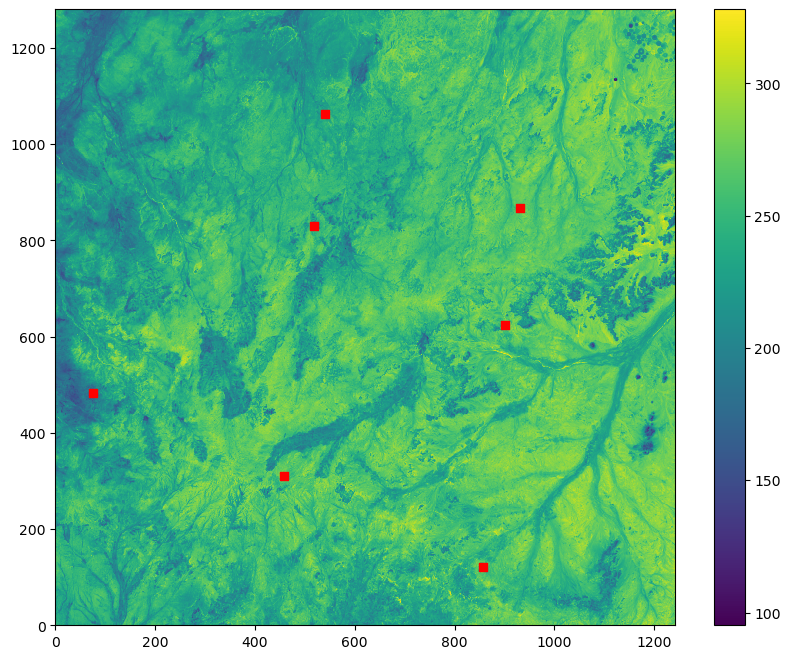

In [27]:
CERES_lons=np.array(CERES_data['Longitude of CERES FOV at surface'][collocation_data['CERES_pixel_index'][0]].values )
CERES_lats=90-np.array(CERES_data['Colatitude of CERES FOV at surface'][collocation_data['CERES_pixel_index'][0]].values )
CERES_Fup=np.array(CERES_data['CERES SW TOA flux - upwards'][collocation_data['CERES_pixel_index'][0]].values)
CERES_F0=np.array(CERES_data['TOA Incoming Solar Radiation'][collocation_data['CERES_pixel_index'][0]].values)
CERES_sza=np.array(CERES_data['CERES solar zenith at surface'][collocation_data['CERES_pixel_index'][0]].values)
CERES_S0 = np.mean(CERES_F0/np.cos(np.radians(CERES_sza)))
S0_ratio = CERES_S0/KS.solar_constant

fig,ax=plt.subplots(figsize=(10,8))
cf=ax.pcolormesh(EMIT_BB_flux)
# print('CERES_lons',CERES_lons)
# print('CERES_lats',CERES_lats)
for i in range(len(CERES_lons)):
    print('lon0,lat0,' ,CERES_lons[i],CERES_lats[i] )
    GCC = great_circle(CERES_lons[i],CERES_lats[i],
                       EMIT_granule_data_dict['OBS_location'].lon.values,
                       EMIT_granule_data_dict['OBS_location'].lat.values)
    sample=(GCC<=20.0)
    print(sample.sum())
    co_yi,co_xi=np.unravel_index(np.nanargmin(GCC), GCC.shape)
    # print(co_yi,co_xi,GCC[co_yi,co_xi],
    #       EMIT_BB_flux[co_yi,co_xi].mean()*S0_ratio/(1342.6956*np.cos(np.cos(20.17))),
    #       CERES_Fup[i]/CERES_F0[i])
    sza=EMIT_granule_data_dict['OBS'].obs[:,:,4].values[sample].mean()
    EMIT_Fup =  EMIT_BB_flux[sample].mean()
    EMIT_Fdn =  (1342.6956*np.cos(np.radians(sza)))
    
    ratio =EMIT_Fup / EMIT_Fdn

    print('Fdn EMIT:CERES',EMIT_Fdn,CERES_F0[i])
    print('Fup EMIT:CERES',EMIT_Fup,CERES_Fup[i])
    print(co_yi,co_xi,GCC[co_yi,co_xi],
          ratio,
          CERES_Fup[i]/CERES_F0[i])
    ax.scatter([co_xi],[co_yi],c='r',marker='s')
fig.colorbar(cf,ax=ax)

In [17]:
EMIT_granule_data_dict['OBS_sensor_band_parameters'].observation_bands.values

array(['Path length (sensor-to-ground in meters)',
       'To-sensor azimuth (0 to 360 degrees CW from N)',
       'To-sensor zenith (0 to 90 degrees from zenith)',
       'To-sun azimuth (0 to 360 degrees CW from N)',
       'To-sun zenith (0 to 90 degrees from zenith)',
       'Solar phase (degrees between to-sensor and to-sun vectors in principal plane)',
       'Slope (local surface slope as derived from DEM in degrees)',
       'Aspect (local surface aspect 0 to 360 degrees clockwise from N)',
       'Cosine(i) (apparent local illumination factor based on DEM slope and aspect and to sun vector)',
       'UTC Time (decimal hours for mid-line pixels)',
       'Earth-sun distance (AU)'], dtype=object)

In [37]:
CERES_sza=np.array(CERES_data['CERES solar zenith at surface'][collocation_data['CERES_pixel_index'][0]].values )
CERES_vza=np.array(CERES_data['CERES viewing zenith at surface'][collocation_data['CERES_pixel_index'][0]].values )
CERES_raa=np.array(CERES_data['CERES relative azimuth at surface'][collocation_data['CERES_pixel_index'][0]].values )
CERES_ADM_values = ADM.interpolate_ADM(CERES_sza,CERES_vza,CERES_raa)
print(CERES_ADM_values)
CERES_F0=np.array(CERES_data['TOA Incoming Solar Radiation'][collocation_data['CERES_pixel_index'][0]].values)
CERES_Fup=np.array(CERES_data['CERES SW TOA flux - upwards'][collocation_data['CERES_pixel_index'][0]].values)
CERES_S0 = CERES_F0/np.cos(np.radians(CERES_sza))
CERES_raw_radiance =np.array(CERES_data['CERES SW radiance - upwards'][collocation_data['CERES_pixel_index'][0]].values)
print('CERES_S0',CERES_S0)
print('CERES_sza',CERES_sza)
print('CERES_vza',CERES_vza)
print('CERES_raa',CERES_raa)
print('CERES_ADM',CERES_ADM_values)
print('CERES_Fup',CERES_Fup)
print('CERES_Fup computed from raw radiance and ADM',CERES_raw_radiance*np.pi/CERES_ADM_values)

IndexError: index 10 is out of bounds for axis 2 with size 10

In [38]:
EMIT_granule_lon_mean = EMIT_granule_data_dict['OBS_location'].lon.values.mean()
EMIT_granule_lat_mean = EMIT_granule_data_dict['OBS_location'].lat.values.mean()
print(EMIT_granule_lon_mean,EMIT_granule_lat_mean)
EMIT_case_year = int(case_stamp[:4])
EMIT_case_month = int(case_stamp[4:6])
EMIT_case_day = int(case_stamp[6:8])
EMIT_case_hour = int(case_stamp[9:11])
print(EMIT_case_year,EMIT_case_month,EMIT_case_day,EMIT_case_hour)
#CERES_file_time_stamp = EMIT_case_year+EMIT_case_month+EMIT_case_day
#print(CERES_file_time_stamp)
time_window_in_hour = 2

6.050086543562527 21.34970204691787
2023 4 25 11


In [39]:
CERES_data_path='/home/ubuntu/Research/EMIT_project/CERES_SSF/'
CERES_file_list=[]
for t in range(-time_window_in_hour,time_window_in_hour+1):
    EMIT_case_datetime = datetime.datetime(EMIT_case_year,EMIT_case_month,EMIT_case_day,EMIT_case_hour)
    d=EMIT_case_datetime+datetime.timedelta(hours=t)
    CERES_time_stamp = '{0:4d}{1:02d}{2:02d}{3:02d}'.format(d.year,d.month,d.day,d.hour)
    print(CERES_time_stamp)
    flist=glob.glob(CERES_data_path+'*Terra*'+CERES_time_stamp+'*.hdf')
    print(CERES_data_path+'*'+CERES_time_stamp+'*.hdf')
    if len(flist) >0:
        CERES_file_list.append(flist[0])


2023042509
/home/ubuntu/Research/EMIT_project/CERES_SSF/*2023042509*.hdf
2023042510
/home/ubuntu/Research/EMIT_project/CERES_SSF/*2023042510*.hdf
2023042511
/home/ubuntu/Research/EMIT_project/CERES_SSF/*2023042511*.hdf
2023042512
/home/ubuntu/Research/EMIT_project/CERES_SSF/*2023042512*.hdf
2023042513
/home/ubuntu/Research/EMIT_project/CERES_SSF/*2023042513*.hdf


In [40]:
print(CERES_file_list)

['/home/ubuntu/Research/EMIT_project/CERES_SSF/CER_SSF_Terra-FM2-MODIS_Edition4A_407405.2023042509.hdf', '/home/ubuntu/Research/EMIT_project/CERES_SSF/CER_SSF_Terra-FM2-MODIS_Edition4A_407405.2023042510.hdf', '/home/ubuntu/Research/EMIT_project/CERES_SSF/CER_SSF_Terra-FM2-MODIS_Edition4A_407405.2023042511.hdf']


### read in all the potential CERES files to be collocated

In [23]:
# # # hdf = pyhdf.SD.SD('FLASH_SSF_Terra-FM1-MODIS_Version4A_403411.2024012411.hdf')
# # # hdf.datasets()
# from pyhdf import SD
# class CERES_SSF(object):
#   def __init__(self,fn):

#     hdf = SD.SD(fn)
#     self.colats=hdf.select("Colatitude of CERES FOV at surface").get()
#     self.lons=hdf.select("Longitude of CERES FOV at surface").get()
#     self.time=hdf.select("Time of observation").get()
#     self.SW_F0=hdf.select("TOA Incoming Solar Radiation").get()
#     self.SW_TOA=hdf.select("CERES SW TOA flux - upwards").get()
#     self.SZA=hdf.select("CERES solar zenith at surface").get()
#     # for k in hdf.datasets():
#     #   print(k)
#     # self.data = {}
#     # for sds in SDS_list:
#     #   print('reading',sds)
#     #   s = hdf.select(sds)
#     #   self.data[sds]=s.get()
#     #   s.endaccess()
#     hdf.end()

In [41]:
CERES_granules={} # dictionary to store CERES data
for f in CERES_file_list:
    CERES_granules[f] = xr.open_dataset(f,engine='netcdf4')

In [42]:
delta_lat = 0.3
delta_lon = 0.3
delta_distance_km = 40.0
EMIT_granule_lat_range = np.array([EMIT_granule_lat_mean-delta_lat,
                                   EMIT_granule_lat_mean+delta_lat])

EMIT_granule_lon_range = np.array([EMIT_granule_lon_mean-delta_lon,
                                   EMIT_granule_lon_mean+delta_lon])

print('EMIT_granule_lat_range',EMIT_granule_lat_range)
print('EMIT_granule_lon_range',EMIT_granule_lon_range)

# EMIT latitude range is between [-90 and 90]
# EMIT longtitude range is between [-180 and 180]

# CERES co-latitude range is between [0 and 180]
# CERES longtitude range is between [0 and 360]

for f in CERES_file_list:
    # print(CERES_granules[f].colats.min(),CERES_granules[f].colats.max(),
    #       CERES_granules[f].lons.min(),CERES_granules[f].lons.max())
    CERES_lats = 90.0-CERES_granules[f]['Colatitude of CERES FOV at surface'].values
    CERES_lons = copy.deepcopy(CERES_granules[f]['Longitude of CERES FOV at surface'].values)
    west_half = CERES_lons>180.0
    CERES_lons[west_half] = CERES_lons[west_half]-360.0
    #CERES_to_EMIT_center_distance = great_circle(EMIT_granule_lon_mean,EMIT_granule_lat_mean,
    #                                             CERES_lons,CERES_lats)
    #in_the_circle = CERES_to_EMIT_center_distance<=delta_distance_km
    #print(CERES_to_EMIT_center_distance.min())
    # print('lat lon range:',CERES_lats.min(),CERES_lats.max(),CERES_lons.min(),CERES_lons.max())
    CERES_in_EMIT_granule= (CERES_lons>(EMIT_granule_lon_range[0])) & \
                           (CERES_lons<(EMIT_granule_lon_range[1])) & \
                           (CERES_lats>(EMIT_granule_lat_range[0])) & \
                           (CERES_lats<(EMIT_granule_lat_range[1]))
    #print(f,CERES_in_EMIT_granule.sum())
    if CERES_in_EMIT_granule.sum() > 0:
        print(f,CERES_in_EMIT_granule.sum())
        break
    #     # print(90-CERES_granules[f].colats[CERES_in_EMIT_granule],
    #     #       CERES_lons[CERES_in_EMIT_granule])

EMIT_granule_lat_range [21.04970205 21.64970205]
EMIT_granule_lon_range [5.75008654 6.35008654]
/home/ubuntu/Research/EMIT_project/CERES_SSF/CER_SSF_Terra-FM2-MODIS_Edition4A_407405.2023042509.hdf 389


In [34]:
# CERES_lons=np.array(CERES_data['Longitude of CERES FOV at surface'][collocation_data['CERES_pixel_index'][0]].values )
# CERES_lats=90-np.array(CERES_data['Colatitude of CERES FOV at surface'][collocation_data['CERES_pixel_index'][0]].values )

#print('CERES_lons',CERES_lons[in_the_circle])
#print('CERES_lats',CERES_lats[in_the_circle])

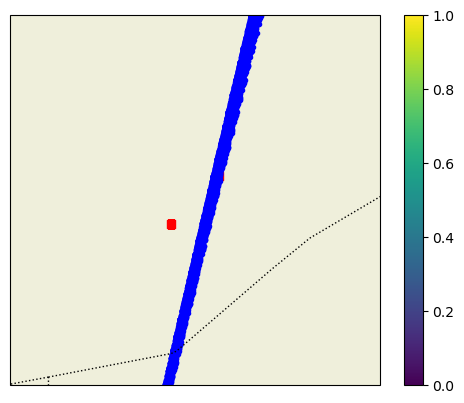

In [46]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
#COUNTIES = cfeature.ShapelyFeature(counties, ccrs.PlateCarree())
ax = plt.axes(projection=ccrs.PlateCarree())
# cf=plt.scatter(x=CERES_granules[f].lons[CERES_in_EMIT_granule]-360.0,\
#                y=90.0-CERES_granules[f].colats[CERES_in_EMIT_granule],\
#                c='k',\
#                transform=ccrs.PlateCarree())

cf=plt.scatter(x=EMIT_granule_lon_range,\
               y=EMIT_granule_lat_range,\
               c='r',marker='s',\
               transform=ccrs.PlateCarree())

# cf=plt.scatter(x=CERES_lons[CERES_in_EMIT_granule],\
#                y=CERES_lats[CERES_in_EMIT_granule],\
#                c='b',marker='o',\
#                transform=ccrs.PlateCarree())

cf=plt.scatter(x=CERES_lons,\
               y=CERES_lats,\
               c='b',marker='.',\
               transform=ccrs.PlateCarree())

stamen_terrain = cimgt.Stamen('terrain-background')
#m10 = plt.axes(projection=stamen_terrain.crs)
ax.set_extent([ EMIT_granule_lon_range[0]-2, EMIT_granule_lon_range[-1]+2,
                EMIT_granule_lat_range[0]-2, EMIT_granule_lat_range[-1]+2], ccrs.PlateCarree())
# m10.add_image(stamen_terrain, 8)
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS)
plt.colorbar(cf,ax=ax)

## multiple case collocation

### collocate all the EMIT files from the  April  of 2023 with CERES

In [6]:
# open and read the L1B_RAD file for the 2023 April collocation
# https://search.earthdata.nasa.gov/downloads/4437679863

with open("EMIT_2023_04_L1B_file_list.txt", "r") as read_in_file:
    L1B_filelist=read_in_file.readlines()

L1B_RAD_filelist = L1B_filelist[0::2]
L1B_OBS_filelist = L1B_filelist[1::2]

nfile_to_collocate = len(L1B_RAD_filelist)
timestamp_of_EMIT_granule = []
date_of_EMIT_granule = []
for L1B_file in L1B_RAD_filelist:
    re_result=re.search('EMIT_L1B_RAD_001_',L1B_file)
    start_pos,end_pos=re_result.span()
    year =int(L1B_file[end_pos:end_pos+4])
    month = int(L1B_file[end_pos+4:end_pos+6])
    day = int(L1B_file[end_pos+6:end_pos+8])
    hour = int(L1B_file[end_pos+9:end_pos+11])
    minute = int(L1B_file[end_pos+11:end_pos+13])
    second = int(L1B_file[end_pos+13:end_pos+15])
    timestamp_of_EMIT_granule.append(L1B_file[end_pos:end_pos+15])
    date_of_EMIT_granule.append(datetime.datetime(year,month,day,hour,minute,second))

In [7]:
print(len(date_of_EMIT_granule))
print(len(timestamp_of_EMIT_granule))

755
755


In [8]:
timestamp_of_EMIT_granule[750]

'20230401T081207'

In [ ]:
# file location of EMIT and CERES data
CERES_data_path='/home/ubuntu/Research/EMIT_project/CERES_SSF/'
CERES_SSF_prefix = 'CER_SSF_Terra-FM2' #'CER_SSF_Aqua-FM3'
collocation_file_path='EMIT_TERRA_CERES_collocation/'
#EMIT_data_path='/home/zzbatmos/zzbatmos_common/Data/EMIT/'
collocation_successful=np.array(np.zeros(nfile_to_collocate), dtype='bool') 
# number of cases
ncases=0 #len(case_files)
# start and end datetime of the collocation range (here It is April of 2023)
# start_date = datetime.datetime(2023,4,1,0,0)
# end_date = datetime.datetime(2023,4,30,12,59)
# print('collocation start time',start_date, 'endtime',end_date)

# time window of EMIT-CERES collocation
collocation_time_window_in_hour = 2
# spatial range of EMIT-CERES collocation
collocation_lat_lon_delta = 0.3

verbose = False

#go through all the EMIT files in the directory
for ifile in range(665,nfile_to_collocate):
    print('processing',ifile)
    print('successfully collocated',ncases)
    if os.path.isfile('EMIT_CERES_collocation/'+\
                      collocation_file_path+\
                      timestamp_of_EMIT_granule[ifile] + '.pkl'):
        print(ifile,'already collocated')
        ncases+=1
        collocation_successful[ifile]=True
        continue
        
    if verbose: print('collocating',L1B_OBS_filelist[ifile])
    EMIT_date=date_of_EMIT_granule[ifile]
    if verbose: print('reading in EMIT data')
    EMIT_data_dict=read_single_EMIT_granule_data(timestamp_of_EMIT_granule[ifile],['OBS'])
    if verbose: print('EMIT data reading finished')
    # read in all the CERES data in the time window
    
    CERES_file_list=[]
    CERES_granules={} # dictionary to store CERES data
    for t in range(-collocation_time_window_in_hour,collocation_time_window_in_hour+1):
        d=EMIT_date+datetime.timedelta(hours=t)
        CERES_time_stamp = '{0:4d}{1:02d}{2:02d}{3:02d}'.format(d.year,d.month,d.day,d.hour)
        #print(CERES_time_stamp,CERES_data_path+'*'+CERES_time_stamp+'*.hdf')
        flist=glob.glob(CERES_data_path+'*'+CERES_SSF_prefix+'*'+CERES_time_stamp+'*.hdf')
        #print(flist)
        if len(flist) >0:
            CERES_file_list.append(flist[0])
            CERES_granules[flist[0]] = CERES_SSF(flist[0])
    if verbose: print('CERES SSF files',CERES_file_list) 
    #spatial collocation
    EMIT_granule_lon_mean = EMIT_data_dict['OBS_location'].lon.mean()
    EMIT_granule_lat_mean = EMIT_data_dict['OBS_location'].lat.mean()
    EMIT_granule_lat_range = np.array([EMIT_granule_lat_mean-collocation_lat_lon_delta,
                                       EMIT_granule_lat_mean+collocation_lat_lon_delta])
    EMIT_granule_lon_range = np.array([EMIT_granule_lon_mean-collocation_lat_lon_delta,
                                       EMIT_granule_lon_mean+collocation_lat_lon_delta])
    # print(EMIT_granule_lat_range)
    # print(EMIT_granule_lon_range)
    # EMIT latitude range is between [-90 and 90]
    # EMIT longtitude range is between [-180 and 180]
    
    # CERES co-latitude range is between [0 and 180]
    # CERES longtitude range is between [0 and 360]
    
    for CERES_file in CERES_file_list:
        CERES_lats = 90.0-CERES_granules[CERES_file].colats
        CERES_lons = copy.deepcopy(CERES_granules[CERES_file].lons)
        west_half = CERES_lons>180.0
        CERES_lons[west_half] = CERES_lons[west_half]-360.0
        CERES_in_EMIT_granule= (CERES_lats>(EMIT_granule_lat_range[0])) & \
                               (CERES_lats<(EMIT_granule_lat_range[1])) & \
                               (CERES_lons>(EMIT_granule_lon_range[0])) & \
                               (CERES_lons<(EMIT_granule_lon_range[1]))
        #print(CERES_in_EMIT_granule.sum())
        if CERES_in_EMIT_granule.sum() > 0:
            EMIT_CERES_collocation_cases={'L1B_OBS_filelist':[],
                              'L1B_RAD_filelist':[],
                              'CERES_file_name':[],
                              'CERES_pixel_index':[]}
            if verbose: print('EMIT file', L1B_OBS_filelist[ifile],
                              'successfully collocated with \n CERES file', CERES_file)
            collocation_successful[ifile] = True
            ncases+=1       
            if (ncases%10==0): 
                print('collocated cases',ncases)
        
            # collocation successful append EMIT data and CERES data to the dictory
            EMIT_CERES_collocation_cases['L1B_OBS_filelist'].append(L1B_OBS_filelist[ifile])
            EMIT_CERES_collocation_cases['L1B_RAD_filelist'].append(L1B_RAD_filelist[ifile])
            EMIT_CERES_collocation_cases['CERES_file_name'].append(CERES_file)
            EMIT_CERES_collocation_cases['CERES_pixel_index'].append(CERES_in_EMIT_granule)
            pkl_savefile = 'EMIT_CERES_collocation/'+\
                           collocation_file_path+\
                           timestamp_of_EMIT_granule[ifile] + '.pkl'
            with open(pkl_savefile, 'wb') as f:
                pickle.dump(EMIT_CERES_collocation_cases, f)
        else:
            if verbose: print('EMIT file', L1B_OBS_filelist[ifile],
                              'cannot be collocated with CERES')
            
                


processing 665
successfully collocated 0
665 already collocated
processing 666
successfully collocated 1
666 already collocated
processing 667
successfully collocated 2
667 already collocated
processing 668
successfully collocated 3
668 already collocated
processing 669
successfully collocated 4
669 already collocated
processing 670
successfully collocated 5
670 already collocated
processing 671
successfully collocated 6
671 already collocated
processing 672
successfully collocated 7
processing 673
successfully collocated 8
processing 674
successfully collocated 9
collocated cases 10
processing 675
successfully collocated 10
processing 676
successfully collocated 11
processing 677
successfully collocated 12
processing 678
successfully collocated 13
processing 679
successfully collocated 14
processing 680
successfully collocated 15
processing 681
successfully collocated 16
processing 682
successfully collocated 17
processing 683
successfully collocated 18
processing 684
successfully col

## Compare Broadband Flux between EMIT and CERES

In [11]:
def EMIT_radiance2flux(EMIT_RAD,EMIT_RAD_sbp,
                       EMIT_OBS,EMIT_OBS_sbp):
    print(EMIT_RAD.radiance)
    wavelength = EMIT_RAD_sbp.wavelengths
    domain_avg_radiance = np.nanmean(EMIT_RAD.radiance.values,axis=(0,1))
    domain_avg_bb_radiance = np.trapz(domain_avg_radiance,wavelength)
    # ADM as pi for the moment
    ADM = np.pi
    domain_avg_bb_flux = ADM*domain_avg_bb_radiance
    return domain_avg_bb_flux
    
    

In [30]:
CERES_data_path='/home/ubuntu/Research/EMIT_project/CERES_SSF/'
CERES_SSF_prefix = 'CER_SSF_Terra-FM2' #'CER_SSF_Aqua-FM3'
collocation_file_path='EMIT_CERES_collocation/EMIT_TERRA_CERES_collocation/'
Collocate_file_list=glob.glob(collocation_file_path+'*.pkl')
Ncases = len(Collocate_file_list)

CERES_cloud_fraction_threshold = 100.0 # the threshold for selecting clear-sky CERES SSF FOV
EMIT_CERES_distance_threshold = 20.0 # there radius to collocate EMIT pixels and CERES FOV. 
                                     # Compute the distance from EMIT pixels to a CERES FOV. 
                                     # smaller than this thredhold then EMIT pixels are in CERES FOV

EMIT_reflectance = []
CERES_reflectance = []


verbose=False

save_fluxe_comparison_result=True

for icase in range(Ncases):
            
    with open(Collocate_file_list[icase], 'rb') as pkl_file:
        collocation_data=pickle.load(pkl_file)
        
    pos = re.search('.pkl',Collocate_file_list[icase])
    EMIT_time_stamp=(Collocate_file_list[icase][pos.span()[0]-15:pos.span()[0]])
    print('processing case',icase,'out of',Ncases, EMIT_time_stamp)
    flux_comparison_results={}
    flux_comparison_results['EMIT_time_stamp']=EMIT_time_stamp
    
    CERES_data=xr.open_dataset(collocation_data['CERES_file_name'][0],engine='netcdf4')
    CERES_flux = CERES_data['CERES SW TOA flux - upwards'].values[collocation_data['CERES_pixel_index'][0]]
    CERES_radiance = CERES_data['CERES SW filtered radiance - upwards'].values[collocation_data['CERES_pixel_index'][0]]
    CERES_radiance_unfiltered = CERES_data['CERES SW radiance - upwards'].values[collocation_data['CERES_pixel_index'][0]]

    CERES_clear_fraction = CERES_data['Clear/layer/overlap percent coverages'].values[collocation_data['CERES_pixel_index'][0]][:,0]
    CERES_clear_sky_pixels = CERES_clear_fraction>=CERES_cloud_fraction_threshold
    CERES_SZA=CERES_data['CERES solar zenith at surface']
    CERES_VZA=CERES_data['CERES viewing zenith at surface']
    CERES_RAZ=CERES_data['CERES relative azimuth at surface']
    CERES_F0=CERES_data['TOA Incoming Solar Radiation']
    
    CERES_S0=np.nanmean(CERES_F0/np.cos(np.radians(CERES_SZA)))
    KS_CERES_S0_ratio = CERES_S0/KS.solar_constant

    flux_comparison_results['CERES_Lon']=[]
    flux_comparison_results['CERES_Lat']=[]
    flux_comparison_results['CERES_S0']=[CERES_S0]
    flux_comparison_results['CERES_Fup_based_on_ADM_filtered']=[]
    flux_comparison_results['CERES_Fup_based_on_ADM_unfiltered']=[]
    flux_comparison_results['CERES_Fup']=[]
    flux_comparison_results['CERES_Fdn']=[]
    flux_comparison_results['CERES_Ref']=[]
    flux_comparison_results['CERES_Sza']=[]
    flux_comparison_results['CERES_Vza']=[]
    flux_comparison_results['CERES_Raz']=[]
    


    flux_comparison_results['EMIT_Fup']=[]
    flux_comparison_results['EMIT_Fdn']=[]
    flux_comparison_results['EMIT_Ref']=[]
    flux_comparison_results['EMIT_Sza']=[]
    flux_comparison_results['EMIT_Vza']=[]
    flux_comparison_results['EMIT_Raz']=[]
    flux_comparison_results['EMIT_Adm']=[]

    if CERES_clear_sky_pixels.sum() ==0: 
        continue
    EMIT_data_dict = read_single_EMIT_granule_data(EMIT_time_stamp,['OBS','RAD'])
    NCERES_clear = CERES_clear_sky_pixels.sum()
    for j in range(NCERES_clear):
        lon0=CERES_data['Longitude of CERES FOV at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]
        lat0=90.0-CERES_data['Colatitude of CERES FOV at surface'].values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]
        flux_comparison_results['CERES_Lon'].append(lon0)
        flux_comparison_results['CERES_Lat'].append(lat0)
        EMIT_lon_array=EMIT_data_dict['OBS_location'].lon.values
        EMIT_lat_array=EMIT_data_dict['OBS_location'].lat.values
        EMIT_CERES_distance=great_circle(lon0,lat0,EMIT_lon_array,EMIT_lat_array)
        EMIT_pixels_in_CERES_FOV = (EMIT_CERES_distance<=EMIT_CERES_distance_threshold)
        EMIT_pixels_in_CERES_FOV_avg_radiance = EMIT_data_dict['RAD'].radiance.values[EMIT_pixels_in_CERES_FOV].mean(axis=0)        
        EMIT_pixels_in_CERES_SZA = EMIT_data_dict['OBS'].obs.values[:,:,4][EMIT_pixels_in_CERES_FOV].mean() # EMIT solar zenith angle (small variation so only needs mean)
        EMIT_pixels_in_CERES_VZA = EMIT_data_dict['OBS'].obs.values[:,:,2][EMIT_pixels_in_CERES_FOV].mean() # EMIT viewing zenith angle (small variation so only needs mean)
        EMIT_pixels_in_CERES_RAZ = EMIT_data_dict['OBS'].obs.values[:,:,1][EMIT_pixels_in_CERES_FOV].mean()-\
                                   EMIT_data_dict['OBS'].obs.values[:,:,3][EMIT_pixels_in_CERES_FOV].mean()
        # print([EMIT_pixels_in_CERES_SZA],[EMIT_pixels_in_CERES_VZA],[EMIT_pixels_in_CERES_RAZ])
        # print( [CERES_SZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]],
        #        [CERES_VZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]],
        #        [CERES_RAZ.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]])
        
        
        ADM_for_EMIT = ADM.interpolate_ADM([EMIT_pixels_in_CERES_SZA],[EMIT_pixels_in_CERES_VZA],[EMIT_pixels_in_CERES_RAZ])
        ADM_for_CERES = ADM.interpolate_ADM( [CERES_SZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]],
                                             [CERES_VZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]],
                                             [CERES_RAZ.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j]])
        #print(j,ADM_for_EMIT,ADM_for_CERES)
        flux_comparison_results['CERES_Sza'].append(CERES_SZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j])
        flux_comparison_results['CERES_Vza'].append(CERES_VZA.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j])
        flux_comparison_results['CERES_Raz'].append(CERES_RAZ.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j])
        flux_comparison_results['CERES_Fup'].append(CERES_flux[j])
        flux_comparison_results['CERES_Fup_based_on_ADM_filtered'].append(CERES_radiance[j]/ADM_for_CERES[0]*np.pi)
        flux_comparison_results['CERES_Fup_based_on_ADM_unfiltered'].append(CERES_radiance_unfiltered[j]/ADM_for_CERES[0]*np.pi)

        flux_comparison_results['CERES_Fdn'].append(CERES_F0.values[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j])
        flux_comparison_results['CERES_Ref'].append(CERES_flux[j]/CERES_F0[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels][j].values)
        # print('CERES Fup', flux_comparison_results['CERES_Fup'][-1],
        #                    flux_comparison_results['CERES_Fup_based_on_ADM_filtered'][-1],
        #                    flux_comparison_results['CERES_Fup_based_on_ADM_unfiltered'][-1])
        EMIT_Fup = np.trapz(EMIT_pixels_in_CERES_FOV_avg_radiance,EMIT_data_dict['RAD_sensor_band_parameters'].wavelengths)*np.pi/100.0/ADM_for_EMIT[0]
        EMIT_Fdn = KS.solar_constant*KS_CERES_S0_ratio*np.cos(np.radians(EMIT_pixels_in_CERES_SZA))
        flux_comparison_results['EMIT_Fup'].append(EMIT_Fup)
        flux_comparison_results['EMIT_Fdn'].append(EMIT_Fdn)
        flux_comparison_results['EMIT_Ref'].append(EMIT_Fup/EMIT_Fdn)
        flux_comparison_results['EMIT_Sza'].append(EMIT_pixels_in_CERES_SZA)
        flux_comparison_results['EMIT_Vza'].append(EMIT_pixels_in_CERES_VZA)
        flux_comparison_results['EMIT_Raz'].append(EMIT_pixels_in_CERES_RAZ)
        flux_comparison_results['EMIT_Adm'].append(ADM_for_EMIT[0])
       
    if save_fluxe_comparison_result:  
        save_file_name='Flux_Comparison/flux_comparison_results_'+EMIT_time_stamp+'.pkl'
        with open(save_file_name,'wb') as dump_file:
            pickle.dump(flux_comparison_results,dump_file)


processing case 0 out of 517 20230428T090356
processing case 1 out of 517 20230424T104250
processing case 2 out of 517 20230426T073229
processing case 3 out of 517 20230406T102850
processing case 4 out of 517 20230401T094634
processing case 5 out of 517 20230404T103107
processing case 6 out of 517 20230406T071731
processing case 7 out of 517 20230405T063607
processing case 8 out of 517 20230428T103632
processing case 9 out of 517 20230426T121831
processing case 10 out of 517 20230404T072514
processing case 11 out of 517 20230403T080920
processing case 12 out of 517 20230408T054607
processing case 13 out of 517 20230430T055608
processing case 14 out of 517 20230401T125336
processing case 15 out of 517 20230429T095134
processing case 16 out of 517 20230401T081207
processing case 17 out of 517 20230405T080927
processing case 18 out of 517 20230430T073103
processing case 19 out of 517 20230430T055631
processing case 20 out of 517 20230406T085032
processing case 21 out of 517 20230405T11174

In [18]:
CERES_data['CERES SW filtered radiance - upwards']

<xarray.DataArray 'CERES SW filtered radiance - upwards' (Footprints: 112036)> Size: 448kB
[112036 values with dtype=float32]
Dimensions without coordinates: Footprints
Attributes:
    units:        Watts per square meter per steradian
    format:       F18.9
    valid_range:  [-10. 510.]

In [47]:
flist = glob.glob('Flux_Comparison/flux_comparison_results_*.pkl')

CERES_reflectance=[]
EMIT_reflectance=[]
CERES_lons=[]
CERES_lats=[]
for f in flist:
    with open(f,'rb') as f:
        flux_comparison_results=pickle.load(f)
    
    if len(flux_comparison_results['CERES_Lon']) ==0: 
        continue
    elif len(flux_comparison_results['CERES_Lon']) >20:
        print(len(flux_comparison_results['CERES_Lon']))
        continue
    #print(flux_comparison_results[k]['CERES_Ref'])
    xx=np.array(flux_comparison_results['CERES_Ref'])#*np.array(flux_comparison_results['CERES_Fup_based_on_ADM_filtered'])/np.array(flux_comparison_results['CERES_Fup'])
    CERES_reflectance+=xx.tolist()
    EMIT_reflectance+=(flux_comparison_results['EMIT_Ref'])
    CERES_lons+=flux_comparison_results['CERES_Lon']
    CERES_lats+=flux_comparison_results['CERES_Lat']
    
CERES_reflectance=(np.array(CERES_reflectance))
EMIT_reflectance=(np.array(EMIT_reflectance))
CERES_lons=np.array(CERES_lons)
CERES_lats=np.array(CERES_lats)

40
30
26
30
29
28
37
66
57
26
25
26
80
29
67
33
56
27
36
56
44
25
22
34
47
60
28
386
22
22
23


1.03480868664094 0.9350122821955393 0.0


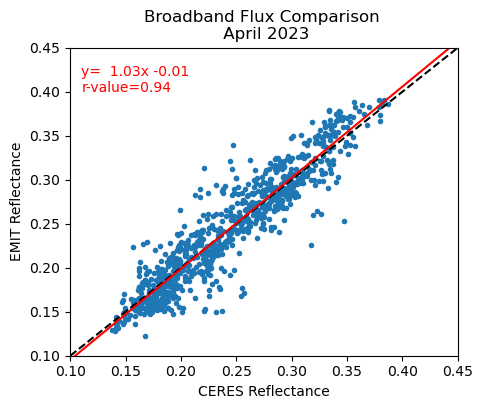

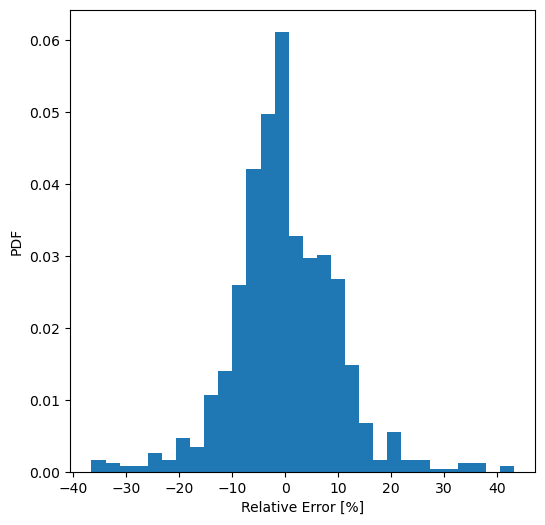

In [48]:
fig,ax=plt.subplots(figsize=(5,4))
ax.scatter(CERES_reflectance,EMIT_reflectance,marker='.')
ax.set_xlim([0.1,0.45])
ax.set_ylim([0.1,0.45])
from scipy.stats import linregress
mask = ~np.isnan(CERES_reflectance) & ~np.isnan(EMIT_reflectance)
slope, intcep, rv,pv,_ = linregress(np.array(CERES_reflectance)[mask],np.array(EMIT_reflectance)[mask])
print(slope,rv,pv)
ax.plot(np.linspace(0.1,0.5,100),np.linspace(0.1,0.5,100),c='k',ls='dashed')
ax.plot(np.linspace(0.1,0.5,100),slope*np.linspace(0.1,0.5,100)+intcep,c='r')
ax.text(0.11,0.40,'y={0:6.2f}x{1:6.2f} \nr-value={2:4.2f}'.format(slope,intcep,rv),c='r')
ax.set_xlabel('CERES Reflectance')
ax.set_ylabel('EMIT Reflectance')
ax.set_title('Broadband Flux Comparison \n April 2023')
fig.savefig('BB_flux_comparison_scatter.png')
# # fig,ax=plt.subplots(figsize=(6,6))
# ax[1].scatter(np.array(CERES_reflectance),np.array(EMIT_reflectance)/np.array(CERES_reflectance)-1.0)
# ax[1].set_xlim([0.1,0.45])
# ax[1].set_ylim([-0.5,0.5])
# ax[1].axhline(0.1,ls='dashed')
# ax[1].axhline(-0.1,ls='dashed')

fig,ax=plt.subplots(figsize=(6,6))
plt.hist(np.array(EMIT_reflectance)/np.array(CERES_reflectance)*100-100.0,bins=30,density=True)
plt.xlabel('Relative Error [%]')
plt.ylabel('PDF')
plt.savefig('BB_flux_comparison_histogram.png')

In [11]:
with open('Flux_Comparison/flux_comparison_results_20230406T071941.pkl','rb') as f:
        flux_comparison_results=pickle.load(f)

In [17]:
flux_comparison_results['EMIT_Raz']

[-30.947174, -63.02604, -64.51955, 24.527603]

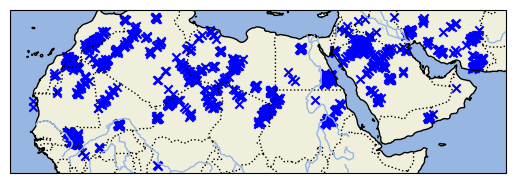

In [45]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
#COUNTIES = cfeature.ShapelyFeature(counties, ccrs.PlateCarree())
ax = plt.axes(projection=ccrs.PlateCarree())

cf=plt.scatter(x=CERES_lons,\
               y=CERES_lats,\
               c='b',marker='x',\
               transform=ccrs.PlateCarree())

stamen_terrain = cimgt.Stamen('terrain-background')
# #m10 = plt.axes(projection=stamen_terrain.crs)
# ax.set_extent([ EMIT_granule_lon_range[0]-2, EMIT_granule_lon_range[-1]+2,
#                 EMIT_granule_lat_range[0]-2, EMIT_granule_lat_range[-1]+2], ccrs.PlateCarree())
# # m10.add_image(stamen_terrain, 8)
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS)
plt.savefig('BB_flux_comparison_locations.png')
#plt.colorbar(cf,ax=ax)

In [33]:
R=np.array(EMIT_reflectance)/np.array(CERES_reflectance)
print(R[22])
print(np.nanargmax(R))
print(EMIT_reflectance[np.nanargmax(R)],CERES_reflectance[np.nanargmax(R)])
print(EMIT_reflectance[np.nanargmax(R)]/CERES_reflectance[np.nanargmax(R)])

print(np.nanargmin(R))
print(EMIT_reflectance[np.nanargmin(R)],CERES_reflectance[np.nanargmin(R)])
print(EMIT_reflectance[np.nanargmin(R)]/CERES_reflectance[np.nanargmin(R)]-1.0)

nan
1024
0.32110427898149646 0.2059345
1.5592544580574212
1
0.15332801963655726 0.23726709
-0.3537746072246396


In [21]:
np.savez('Reflectance_comparison.npz',CERES_reflectance=CERES_reflectance,
                                      EMIT_reflectance=EMIT_reflectance)

In [82]:
CERES_F0[collocation_data['CERES_pixel_index'][0]][CERES_clear_sky_pixels].values

array([1203.2942, 1205.1238, 1204.6478, 1206.2202, 1207.7554, 1208.6249,
       1205.7736, 1207.3632], dtype=float32)

In [40]:
print(EMIT_data_dict['OBS_sensor_band_parameters'].observation_bands.values)

['Path length (sensor-to-ground in meters)'
 'To-sensor azimuth (0 to 360 degrees CW from N)'
 'To-sensor zenith (0 to 90 degrees from zenith)'
 'To-sun azimuth (0 to 360 degrees CW from N)'
 'To-sun zenith (0 to 90 degrees from zenith)'
 'Solar phase (degrees between to-sensor and to-sun vectors in principal plane)'
 'Slope (local surface slope as derived from DEM in degrees)'
 'Aspect (local surface aspect 0 to 360 degrees clockwise from N)'
 'Cosine(i) (apparent local illumination factor based on DEM slope and aspect and to sun vector)'
 'UTC Time (decimal hours for mid-line pixels)' 'Earth-sun distance (AU)']


In [47]:
print(EMIT_data_dict['OBS'].obs.values[:,:,4].std())

0.22521928


In [8]:
import netCDF4

In [17]:
d=xr.open_dataset(collocation_data['CERES_file_name'][0],engine='netcdf4')

In [27]:
d['Clear/layer/overlap percent coverages'].shape

(111553, 4)